# Chapter 1 — The Toy Example: How You Can Trail in Round 1 and Win Round 2, With No Fraud at All

## The story so far

Brazil elects its president in **two rounds**. Here is the whole rule, in one paragraph:

> In **round 1**, everybody votes for whoever they like. If one candidate gets **more than 50% of the valid votes** (votes for a candidate — blank and spoiled votes don't count), they win immediately and there is no round 2. If nobody passes 50%, the **top two** candidates go to **round 2**, a few weeks later, and whoever gets more votes there wins. Voters whose favourite was eliminated have to pick someone else, stay home, or spoil their ballot. And some people who stayed home in round 1 may show up in round 2.

That last sentence is the whole story of this chapter — and, as Chapter 3 will show, a large part of the story of 2026. A comeback between rounds does not require anyone to cheat. It only requires two perfectly ordinary things:

1. **Vote transfer** — voters for eliminated candidates pick one of the two finalists in round 2.
2. **Turnout change** — different people show up in round 2 than in round 1.

Watch both happen with 100 toy voters. These numbers are invented for teaching — they are *not* the real 2026 numbers — but their shape is deliberately close to 2026 (a narrow round-1 lead, several eliminated candidates), so the lesson transfers.

In [1]:
# Install what this notebook needs (safe to re-run; needed on Google Colab)
!pip install -q pandas matplotlib

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

In [2]:
from pathlib import Path
import pandas as pd, matplotlib.pyplot as plt
# Find the repo root: works whether the notebook is run from notebooks/ or from the repo root.
def find_root():
    for cand in [Path(".."), Path("."), Path("/content/brazil-2026-elections")]:
        if (cand / "data" / "processed").exists():
            return cand
    return Path("..")
ROOT = find_root()
PROC = ROOT / "data" / "processed"
CHARTS = ROOT / "charts"
CHARTS.mkdir(exist_ok=True)
plt.rcParams["figure.dpi"] = 120
print("Data folder:", PROC.resolve())

Data folder: /home/hatch/workspace/brazil-2026-elections/data/processed


## Toy A — Transfer + turnout, together

**Round 1 (100 valid votes).** Nobody passes 50, so the top two go through:

| Candidate | Round-1 votes | Round-1 share |
|---|---|---|
| A (the leader) | 47 | 47% |
| B (the trailer) | 45 | 45% |
| C (eliminated) | 5 | 5% |
| D (eliminated) | 3 | 3% |

Now round 2. C's and D's voters have to choose again, and 4 people who stayed home in round 1 decide to vote this time. Suppose:

- Of C's 5 voters: 3 go to B, 1 goes to A, 1 stays home.
- Of D's 3 voters: 2 go to B, 1 goes to A.
- Of the 4 brand-new voters: 3 go to B, 1 goes to A.
- Nobody who voted for A or B in round 1 switches sides or stays home (we keep it simple on purpose).

Add it up:

In [3]:
# Toy A arithmetic — every number below is counted, not asserted.
r1 = {"A": 47, "B": 45, "C": 5, "D": 3}
# transfers: (to A, to B, stays home) for each eliminated candidate
transfers = {"C": (1, 3, 1), "D": (1, 2, 0)}
new_voters = (1, 3)  # (to A, to B) from people who abstained in round 1
r2_A = r1["A"] + transfers["C"][0] + transfers["D"][0] + new_voters[0]
r2_B = r1["B"] + transfers["C"][1] + transfers["D"][1] + new_voters[1]
print(f"Round 2: A = 47 + 1 (from C) + 1 (from D) + 1 (new) = {r2_A}")
print(f"Round 2: B = 45 + 3 (from C) + 2 (from D) + 3 (new) = {r2_B}")
print(f"Round 2 total valid votes: {r2_A + r2_B}  (was 100; 1 C voter stayed home, 4 new voters arrived)")
print(f"Round 2 shares: A {r2_A/(r2_A+r2_B)*100:.1f}%, B {r2_B/(r2_A+r2_B)*100:.1f}%")
print()
print("B trailed by 2 votes in round 1 and won by 6 in round 2.")
print("No vote was invented, no vote was changed, no voter voted twice.")
print("B simply picked up more of the voters who had to choose again, plus more of the new arrivals.")

Round 2: A = 47 + 1 (from C) + 1 (from D) + 1 (new) = 50
Round 2: B = 45 + 3 (from C) + 2 (from D) + 3 (new) = 53
Round 2 total valid votes: 103  (was 100; 1 C voter stayed home, 4 new voters arrived)
Round 2 shares: A 48.5%, B 51.5%

B trailed by 2 votes in round 1 and won by 6 in round 2.
No vote was invented, no vote was changed, no voter voted twice.
B simply picked up more of the voters who had to choose again, plus more of the new arrivals.


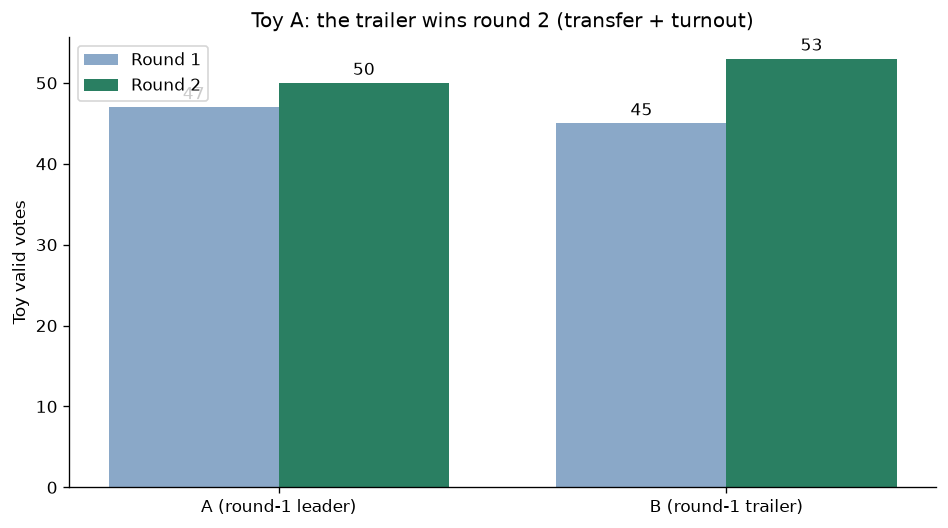

In [4]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(8, 4.5))
labels = ["A (round-1 leader)", "B (round-1 trailer)"]
r1_vals = [47, 45]; r2_vals = [r2_A, r2_B]
x = range(len(labels)); w = 0.38
ax.bar([i - w/2 for i in x], r1_vals, width=w, label="Round 1", color="#8aa8c8")
ax.bar([i + w/2 for i in x], r2_vals, width=w, label="Round 2", color="#2a7f62")
for i, v in enumerate(r1_vals): ax.text(i - w/2, v + 1, str(v), ha="center")
for i, v in enumerate(r2_vals): ax.text(i + w/2, v + 1, str(v), ha="center")
ax.set_xticks(list(x)); ax.set_xticklabels(labels)
ax.set_ylabel("Toy valid votes"); ax.set_title("Toy A: the trailer wins round 2 (transfer + turnout)")
ax.legend(); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.savefig(CHARTS / "01_toy.png"); plt.show()

## Toy B — Turnout alone can do it

Now remove transfer entirely. Suppose every eliminated candidate's voters simply stay home in round 2, so A keeps 47 and B keeps 45 — but **10 new voters** show up, and all 10 vote for B (say round 2 feels more decisive to them, or B's campaign mobilised them).

Then round 2 is A 47, B 55. B wins — and not a single voter changed their mind. Only *who showed up* changed.

That is why, whenever you see a runoff comeback, the first two questions a data analyst asks are never "was there fraud?" but:

1. **How big was the pool of eliminated-candidate votes?** (In 2026: about 9.3 million — Chapter 3.)
2. **How much did turnout move between rounds?** (In 2026: up by about 3.0 million voters — Chapter 3.)

If those two pools, plus blank/null voters changing their minds, are big enough to cover the winner's gain, then the comeback is *arithmetically possible* without any fraud — which is not the same as proving there was none (Chapter 5 is careful about that distinction), but it does mean "the trailer won" is not, by itself, evidence of anything suspicious.

## What this chapter does NOT show

- It does not show what real voters did. Real voters are not tracked individually — the TSE publishes totals per municipality, not per person. Chapter 3 estimates flows from those totals and states its uncertainty in plain words.
- It does not show that transfer and turnout *did* explain 2026. That is Chapter 3's job, with real data.

**Takeaway.** A two-round system is *designed* so that the round-1 leader can lose. The eliminated voters and the stay-at-home voters are the kingmakers of round 2. Next: the real 2026 story, with real numbers.